## Задание 1. 
Используя уравнения фильтра Калмана определите «точные координаты» разгрузки самосвала. 

In [22]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import math
import pandas as pd
import numpy as np
import datetime as dt
import sys
import configparser
import os

pd.set_option('display.max_rows', 1000)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

mainpath=os.path.abspath(os.getcwd())
print(mainpath)
os.chdir(mainpath)

c:\Users\Amega\barnacle\fantastic-barnacle\DataAnalysis\lab3\route4


In [26]:
data = pd.read_csv(mainpath+'\\1_w.csv', sep=';',encoding='cp1251')

display(data.head(3))

,Unnamed: 0,len,Скорость,Широта,Долгота,Вес мгновенный,Продольный наклон,Поперечный наклон,Высота,"Уровень топлива, литры","Уровень топлива, проценты",путь,ДВС.Расход топлива,Ускорение по оси X,Ускорение по оси Y,Ускорение по оси Z,Статус самосвала,Самосвал,Модель самосвала,Грузоподъемность,Обороты двигателя,Расчетный выходной крутящий момент двигателя (в процентах от эталонного),Текущая нагрузка двигателя,Давление в левой передней шине,Температура в левой передней шине,Давление в правой передней шине,Температура в правой передней шине,Давление в левой задней внешней шине,Температура в левой задней внешней шине,Давление в левой задней внутренней шине,Температура в левой задней внутренней шине,Давление в правой задней внутренней шине,Температура в правой задней внутренней шине,Давление в правой задней внешней шине,Температура в правой задней внешней шине,Расход топлива,Давление левый передний цилиндр,Давление правый передний цилиндр,Давление левый задний цилиндр,Давление правый задний цилиндр,уклон,azimut,isin_border,Давление левый передний цилиндр_,Давление правый передний цилиндр_,Давление левый задний цилиндр_,Давление правый задний цилиндр_,point,nom_point,"уровень давления впереди,МПа","уровень давления сзади,МПа",рекомендованная скорость_turns,Поворот влево,Поворот вправо,centr,radius,подъем,спуск,рекомендованная скорость_min,рекомендованная скорость_max
0,0,0.0,7.0,53.727590,86.854016,202.0,4.158987,3.245764,1.299945,2446.0,88.8,0.000000,119.925,0.027531,-0.939125,-0.068319,Груженный движется вперед,95,7530G,240,945.0,49.0,100.0,800.0,29.0,808.0,26.0,888.0,46.0,888.0,41.0,8.0,40.0,856.0,45.0,0.133250,6.6,11.0,7.8,14.3,4.626917,-1.305806,0,7.2,10.44,10.1,14.645,point_30%,1,7.2,10.1,0.0,0,0,-,0.0,0,0,0.0,0.0
1,1,8.0,7.0,53.727520,86.854048,207.0,5.604727,1.894424,1.406299,2446.0,87.6,8.097400,267.225,0.011216,-0.987050,-0.096870,Груженный движется вперед,95,7530G,240,1404.0,77.0,100.0,800.0,29.0,808.0,26.0,888.0,46.0,888.0,41.0,8.0,40.0,856.0,45.0,0.430167,3.8,8.0,10.3,10.8,3.157684,-1.369111,0,7.2,10.44,10.1,14.645,point_30%,1,7.2,10.1,0.0,0,0,-,0.0,0,0,0.0,0.0
2,2,17.0,9.0,53.727444,86.854075,205.0,0.415264,0.729007,1.384253,2446.0,86.8,8.646824,153.400,0.060161,-0.982971,-0.007138,Груженный движется вперед,95,7530G,240,1053.0,58.0,100.0,800.0,29.0,808.0,26.0,888.0,46.0,888.0,41.0,8.0,40.0,856.0,45.0,0.600611,5.6,8.9,8.0,13.4,1.914892,-1.224417,0,7.2,10.44,10.1,14.645,point_30%,1,7.2,10.1,0.0,0,0,-,0.0,0,0,0.0,0.0


In [ ]:
# intial parameters
n_iter = 50
sz = (n_iter,) # size of array
x = -0.37727 # truth value (typo in example at top of p. 13 calls this z)
z = np.random.normal(x,0.1,size=sz) # observations (normal about x, sigma=0.1)

Q = 1e-5 # process variance

# allocate space for arrays
xhat=np.zeros(sz)      # a posteri estimate of x
P=np.zeros(sz)         # a posteri error estimate
xhatminus=np.zeros(sz) # a priori estimate of x
Pminus=np.zeros(sz)    # a priori error estimate
K=np.zeros(sz)         # gain or blending factor

R = 0.1**2 # estimate of measurement variance, change to see effect

<>:49: SyntaxWarning: invalid escape sequence '\i'
<>:49: SyntaxWarning: invalid escape sequence '\i'
C:\Users\Amega\AppData\Local\Temp\ipykernel_10664\3715863276.py:49: SyntaxWarning: invalid escape sequence '\i'
  plt.title('Estimated $\it{\mathbf{a \ priori}}$ error vs. iteration step', fontweight='bold')


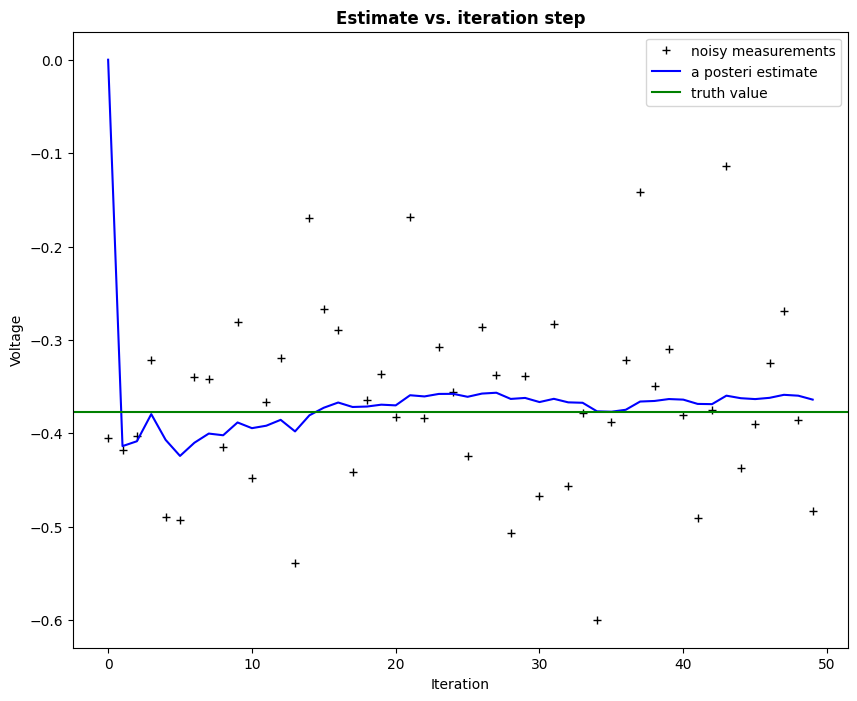

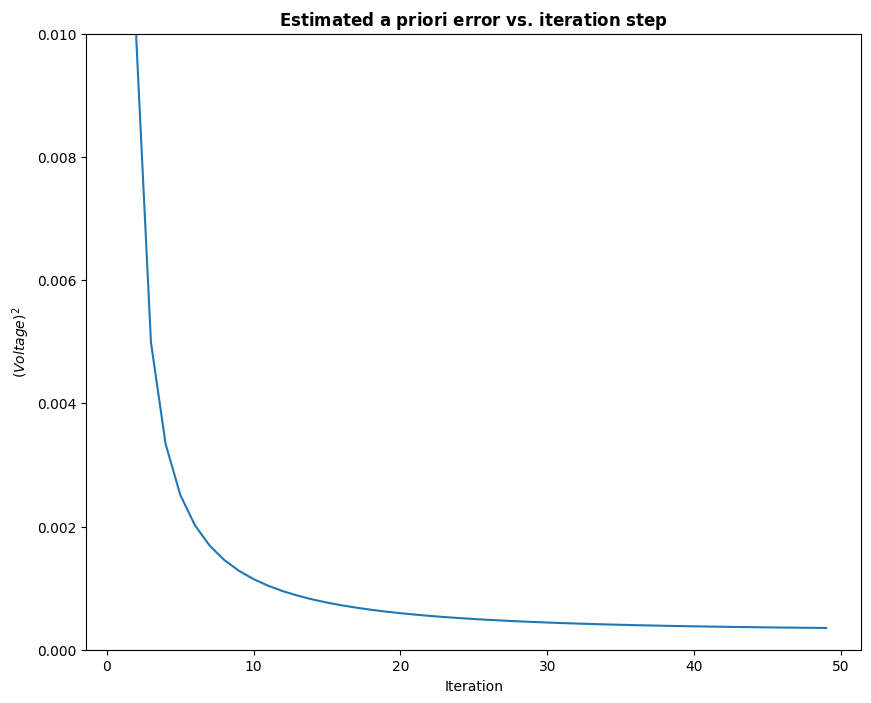

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 8)

# intial parameters
n_iter = 50
sz = (n_iter,) # size of array
x = -0.37727 # truth value (typo in example at top of p. 13 calls this z)
z = np.random.normal(x,0.1,size=sz) # observations (normal about x, sigma=0.1)

Q = 1e-5 # process variance

# allocate space for arrays
xhat=np.zeros(sz)      # a posteri estimate of x
P=np.zeros(sz)         # a posteri error estimate
xhatminus=np.zeros(sz) # a priori estimate of x
Pminus=np.zeros(sz)    # a priori error estimate
K=np.zeros(sz)         # gain or blending factor

R = 0.1**2 # estimate of measurement variance, change to see effect

# intial guesses
xhat[0] = 0.0
P[0] = 1.0

for k in range(1, n_iter):
    # time update
    xhatminus[k] = xhat[k-1]
    Pminus[k] = P[k-1]+Q

    # measurement update
    K[k] = Pminus[k]/( Pminus[k]+R )
    xhat[k] = xhatminus[k]+K[k]*(z[k]-xhatminus[k])
    P[k] = (1-K[k])*Pminus[k]

plt.figure()
plt.plot(z,'k+',label='noisy measurements')
plt.plot(xhat,'b-',label='a posteri estimate')
plt.axhline(x,color='g',label='truth value')
plt.legend()
plt.title('Estimate vs. iteration step', fontweight='bold')
plt.xlabel('Iteration')
plt.ylabel('Voltage')

plt.figure()
valid_iter = range(1,n_iter) # Pminus not valid at step 0
plt.plot(valid_iter,Pminus[valid_iter],label='a priori error estimate')
plt.title('Estimated $\it{\mathbf{a \ priori}}$ error vs. iteration step', fontweight='bold')
plt.xlabel('Iteration')
plt.ylabel('$(Voltage)^2$')
plt.setp(plt.gca(),'ylim',[0,.01])
plt.show()

In [57]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np
import pandas as pd
import os
import sys
from itertools import product

# ===============================
# 1. Загрузка данных для всех дорог (фиксированный путь)
# ===============================
def load_truck_data(filepath, encoding='cp1251'):
    """Загружает один CSV-файл"""
    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Файл {filepath} не найден.")
    
    df = pd.read_csv(filepath, sep=';', encoding=encoding, decimal='.')
    
    # Определяем столбцы по названиям (кириллица)
    lat_col = None
    lon_col = None
    status_col = None
    speed_col = None
    for col in df.columns:
        col_low = col.lower()
        if 'широта' in col_low:
            lat_col = col
        elif 'долгота' in col_low:
            lon_col = col
        elif 'статус' in col_low:
            status_col = col
        elif 'скорость' in col_low:
            speed_col = col
    
    
    lat = pd.to_numeric(df[lat_col], errors='coerce')
    lon = pd.to_numeric(df[lon_col], errors='coerce')
    speed = pd.to_numeric(df[speed_col], errors='coerce')
    status = df[status_col].astype(str).str.strip()
    
    df_clean = pd.DataFrame({
        'широта': lat,
        'долгота': lon,
        'статус': status,
        'скорость': speed,
        'временной_индекс': np.arange(len(df))
    })
    
    df_clean = df_clean.dropna(subset=['широта', 'долгота', 'скорость'])
    return df_clean

def load_all_routes(base_dir, file_pattern='{}_w.csv', encoding='cp1251'):
    """
    Загружает данные для четырёх дорог.
    base_dir: полный путь к папке с файлами 
    """
    routes = ['Д1', 'Д2', 'Д3', 'Д4']
    data = {}
    for i, route in enumerate(routes, start=1):
        filename = file_pattern.format(i)
        filepath = os.path.join(base_dir, filename)
        if not os.path.exists(filepath):
            print(f"Предупреждение: файл {filepath} не найден, пропускаем")
            continue
        try:
            df = load_truck_data(filepath, encoding=encoding)
            print(f"Загружена дорога {route} из {filepath}: {len(df)} записей")
            data[route] = df
        except Exception as e:
            print(f"Ошибка при загрузке {route}: {e}")
    return data

# ===============================
# 2. Перевод градусов в метры
# ===============================
def lat_lon_to_xy(df, ref_lat=None, ref_lon=None):
    if ref_lat is None:
        ref_lat = df['широта'].iloc[0]
    if ref_lon is None:
        ref_lon = df['долгота'].iloc[0]
    ref_lat_rad = np.radians(ref_lat)
    m_per_deg_lat = 111320.0
    m_per_deg_lon = 111320.0 * np.cos(ref_lat_rad)
    df = df.copy()
    df['x'] = (df['долгота'] - ref_lon) * m_per_deg_lon
    df['y'] = (df['широта'] - ref_lat) * m_per_deg_lat
    return df

# ===============================
# 3. Фильтр Калмана (раздельные σ_x, σ_y)
# ===============================
class KalmanFilter:
    def __init__(self, dt, sigma_a=0.5, sigma_x=5.0, sigma_y=5.0):
        self.dt = dt
        self.F = np.array([[1, dt, 0, 0],
                           [0, 1, 0, 0],
                           [0, 0, 1, dt],
                           [0, 0, 0, 1]])
        self.G = np.array([[dt**2/2, 0],
                           [dt, 0],
                           [0, dt**2/2],
                           [0, dt]])
        self.H = np.array([[1, 0, 0, 0],
                           [0, 0, 1, 0]])
        sigma_a2 = sigma_a**2
        q11 = (dt**4)/4 * sigma_a2
        q12 = (dt**3)/2 * sigma_a2
        q22 = dt**2 * sigma_a2
        self.Q = np.array([[q11, q12, 0, 0],
                           [q12, q22, 0, 0],
                           [0, 0, q11, q12],
                           [0, 0, q12, q22]])
        self.R = np.array([[sigma_x**2, 0],
                           [0, sigma_y**2]])
        self.x_est = np.zeros(4)
        self.P = np.eye(4) * 100.0

    def predict(self, u=np.zeros(2)):
        self.x_pred = self.F @ self.x_est + self.G @ u
        self.P_pred = self.F @ self.P @ self.F.T + self.Q
        return self.x_pred

    def update(self, z):
        S = self.H @ self.P_pred @ self.H.T + self.R
        K = self.P_pred @ self.H.T @ np.linalg.inv(S)
        self.x_est = self.x_pred + K @ (z - self.H @ self.x_pred)
        self.P = (np.eye(4) - K @ self.H) @ self.P_pred
        return self.x_est, K

def apply_kalman(df, dt=1.0, sigma_a=0.5, sigma_x=5.0, sigma_y=5.0):
    kf = KalmanFilter(dt, sigma_a, sigma_x, sigma_y)
    n = len(df)
    x_k = np.zeros(n)
    y_k = np.zeros(n)
    for i in range(n):
        z = np.array([df.loc[i, 'x'], df.loc[i, 'y']])
        kf.predict()
        x_est, _ = kf.update(z)
        x_k[i] = x_est[0]
        y_k[i] = x_est[2]
    df = df.copy()
    df['x_kalman'] = x_k
    df['y_kalman'] = y_k
    return df

def task1_for_route(df, route_name):
    print(f"\n--- Дорога {route_name} ---")
    df_xy = lat_lon_to_xy(df)
    df_filt = apply_kalman(df_xy, dt=1.0, sigma_a=0.5, sigma_x=5.0, sigma_y=5.0)
    unloading_mask = (df_filt['статус'].str.contains('стоит', na=False)) & (df_filt['скорость'] == 0)
    unloading = df_filt[unloading_mask]
    if len(unloading) == 0:
        print(f"  Нет событий разгрузки для {route_name}")
        return None
    var_x = unloading['x_kalman'].var()
    var_y = unloading['y_kalman'].var()
    print(f"  Дисперсия разгрузки: σ²(x) = {var_x:.2f} м², σ²(y) = {var_y:.2f} м²")
    print(f"  Средние координаты: x = {unloading['x_kalman'].mean():.2f} м, y = {unloading['y_kalman'].mean():.2f} м")
    return var_x, var_y

# ===============================
# Задание 2: максимальное количество самосвалов (по условию)
# ===============================
def compute_cycle_times():
    cycles = {
        'Д1': {'load': 2, 'loaded': 15, 'unload': 5, 'empty': 15-2},
        'Д2': {'load': 2, 'loaded': 10, 'unload': 5, 'empty': 10-2},
        'Д3': {'load': 2, 'loaded': 20, 'unload': 5, 'empty': 20-2},
        'Д4': {'load': 2, 'loaded': 15, 'unload': 5, 'empty': 15-2}
    }
    for key, val in cycles.items():
        val['total'] = val['load'] + val['loaded'] + val['unload'] + val['empty']
    return cycles

def max_trucks_per_road(wait_limit=5.0):
    cycles = compute_cycle_times()
    S = 5.0
    max_x = {}
    print("\n=== Задание 2 ===")
    for road, data in cycles.items():
        T = data['total']
        a = S / T
        x_max_float = (2 * wait_limit) / (a * (S + 2 * wait_limit)) if a != 0 else 0
        max_x[road] = int(np.floor(x_max_float))
        print(f"Максимум на {road}: {max_x[road]} самосвалов (простой ≤ {wait_limit} мин)")
    return max_x

# ===============================
# Задание 3: оптимизация количества самосвалов
# ===============================
def task3(gruzopod, third_index=0, max_x_dict=None, total_trucks_limit=30):
    склады = {
        'Д1': {'склад': 'C', 'Ni': 2.28, 'Cu': 2.36, 'план': [2400, 1200, 3300]},
        'Д2': {'склад': 'К_б', 'Ni': 1.8, 'Cu': 1.9, 'план': [500, 500, 410]},
        'Д3': {'склад': 'К_м', 'Ni': 0.56, 'Cu': 1.17, 'план': [450, 550, 550]},
        'Д4': {'склад': 'Т', 'Ni': 1.98, 'Cu': 2.82, 'план': [1600, 1900, 2300]}
    }
    target = {
        0: {'Ni': 1.58, 'Cu': 2.66},
        1: {'Ni': 1.58, 'Cu': 2.44},
        2: {'Ni': 1.57, 'Cu': 2.58}
    }
    plan = {road: data['план'][third_index] for road, data in склады.items()}
    target_Ni = target[third_index]['Ni']
    target_Cu = target[third_index]['Cu']
    
    cycles = compute_cycle_times()
    T_cycle = {road: data['total'] for road, data in cycles.items()}
    prod_one = {road: gruzopod * (60 / T_cycle[road]) for road in T_cycle}
    
    if max_x_dict is None:
        max_x_dict = {road: 30 for road in T_cycle}
    
    roads = ['Д1', 'Д2', 'Д3', 'Д4']
    best_x = None
    best_obj = float('inf')
    best_metrics = {}
    
    ranges = [range(0, max_x_dict[r] + 1) for r in roads]
    for x1, x2, x3, x4 in product(*ranges):
        x = [x1, x2, x3, x4]
        if sum(x) > total_trucks_limit:
            continue
        supply = {road: prod_one[road] * x[i] * 8 for i, road in enumerate(roads)}
        if not all(supply[road] >= plan[road] - 1e-5 for road in roads):
            continue
        total_tonnage = sum(prod_one[road] * x[i] for i, road in enumerate(roads))
        if total_tonnage <= 0:
            continue
        Ni_mix = sum(prod_one[road] * x[i] * (склады[road]['Ni']/100) for i, road in enumerate(roads)) / total_tonnage * 100
        Cu_mix = sum(prod_one[road] * x[i] * (склады[road]['Cu']/100) for i, road in enumerate(roads)) / total_tonnage * 100
        
        if third_index == 0:
            obj = (Ni_mix - target_Ni)**2 + (Cu_mix - target_Cu)**2
        elif third_index == 1:
            obj = (Ni_mix - target_Ni)**2
        else:
            obj = (Cu_mix - target_Cu)**2
        
        if obj < best_obj - 1e-6:
            best_obj = obj
            best_x = x.copy()
            best_metrics = {
                'Ni_mix': Ni_mix,
                'Cu_mix': Cu_mix,
                'total_tonnage': total_tonnage,
                'supply': supply.copy()
            }
    
    if best_x is None:
        print("Не найдено комбинаций, удовлетворяющих плану.")
        return None
    
    print("\n=== Задание 3 ===")
    print(f"Треть списка: {third_index+1} (план смены {third_index+1})")
    print(f"Целевое содержание: Ni={target_Ni}%, Cu={target_Cu}%")
    print(f"Грузоподъемность самосвала = {gruzopod} т")
    for i, road in enumerate(roads):
        print(f"  {road}: {best_x[i]} шт.")
    print(f"Суммарно: {sum(best_x)} самосвалов (≤ {total_trucks_limit})")
    print(f"Достигнутое содержание: Ni={best_metrics['Ni_mix']:.3f}%, Cu={best_metrics['Cu_mix']:.3f}%")
    print(f"Отклонение: ΔNi={abs(best_metrics['Ni_mix']-target_Ni):.3f}%, ΔCu={abs(best_metrics['Cu_mix']-target_Cu):.3f}%")
    return best_x, best_metrics

# ===============================
# Основная программа
# ===============================
if __name__ == "__main__":
    # Укажите полный путь к папке route4
    base_dir = "c:/Users/Amega/barnacle/fantastic-barnacle/DataAnalysis/lab3/route4"
    # Загружаем данные для всех дорог
    routes_data = load_all_routes(base_dir, file_pattern='{}_w.csv', encoding='cp1251')
    if not routes_data:
        print("Не удалось загрузить данные ни для одной дороги. Проверьте путь и наличие файлов 1_w.csv, 2_w.csv, 3_w.csv, 4_w.csv.")
        sys.exit(1)
    
    print("\n" + "="*50)
    print("ЗАДАНИЕ 1: Фильтр Калмана и дисперсия разгрузки")
    print("="*50)
    for route, df in routes_data.items():
        task1_for_route(df, route)
    
    # Задание 2
    print("\n" + "="*50)
    print("ЗАДАНИЕ 2: максимизация")
    print("="*50)
    max_limits = max_trucks_per_road(wait_limit=5.0)
    
    # Определение грузоподъемности (читаем из первого файла, если есть колонка)
    груз = 50.0  # значение по умолчанию
    try:
        # Берём первый загруженный DataFrame
        any_df = next(iter(routes_data.values()))
        # Пытаемся найти исходный CSV, чтобы прочитать грузоподъемность
        for route, df in routes_data.items():
            if 'Грузоподъемность' in df.columns:
                груз = float(df['Грузоподъемность'].iloc[0])
                print(f"\nГрузоподъемность из данных: {груз} т")
                break
    except Exception as e:
        print(f"\nНе удалось определить грузоподъемность, используется {груз} т")
    
    # Задание 3
    print("\n" + "="*50)
    print("ЗАДАНИЕ 3: Оптимизация количества самосвалов")
    print("="*50)
    for third in range(3):
        task3(груз, third_index=third, max_x_dict=max_limits, total_trucks_limit=30)

Загружена дорога Д1 из c:/Users/Amega/barnacle/fantastic-barnacle/DataAnalysis/lab3/route4\1_w.csv: 210 записей
Загружена дорога Д2 из c:/Users/Amega/barnacle/fantastic-barnacle/DataAnalysis/lab3/route4\2_w.csv: 206 записей
Загружена дорога Д3 из c:/Users/Amega/barnacle/fantastic-barnacle/DataAnalysis/lab3/route4\3_w.csv: 196 записей
Загружена дорога Д4 из c:/Users/Amega/barnacle/fantastic-barnacle/DataAnalysis/lab3/route4\4_w.csv: 199 записей

ЗАДАНИЕ 1: Фильтр Калмана и дисперсия разгрузки

--- Дорога Д1 ---
  Дисперсия разгрузки: σ²(x) = 203873.93 м², σ²(y) = 65059.02 м²
  Средние координаты: x = -5.92 м, y = 3253.95 м

--- Дорога Д2 ---
  Дисперсия разгрузки: σ²(x) = nan м², σ²(y) = nan м²
  Средние координаты: x = 721.69 м, y = 2899.94 м

--- Дорога Д3 ---
  Дисперсия разгрузки: σ²(x) = 933826.68 м², σ²(y) = 166123.91 м²
  Средние координаты: x = 54.46 м, y = 2641.61 м

--- Дорога Д4 ---
  Дисперсия разгрузки: σ²(x) = nan м², σ²(y) = nan м²
  Средние координаты: x = 1465.39 м, y =